# Compare your data to mobility laws

Human jump lengths are known to follow a truncated power law. This notebook computes the jump lengths of the Brightkite check-ins with `jump_lengths` and fits that law with `fit_values_to_truncated_powerlaw`, whose grid search runs in Rust.

In [1]:
import fastmob
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

path = "../../../tests/shared/data/loc-brightkite_totalCheckins.txt.gz"
df = pd.read_csv(path, sep="\t", header=0, names=["uid", "datetime", "lat", "lng", "location id"])
tdf = fastmob.TrajDataFrame(df, sort=True)
len(tdf)

4747280

## Jump lengths

`jump_lengths` returns one list of distances in kilometres per user. Concatenate them and keep the positive ones, since the fit works on the log-histogram.

In [2]:
jumps = tdf.jump_lengths()
values = np.concatenate(jumps["jump_lengths"].to_list())
values = values[np.isfinite(values) & (values > 0)]
f"{len(values):,} jumps, median {np.median(values):.1f} km"

'2,025,563 jumps, median 9.2 km'

## Fit the truncated power law

The fit returns the four parameters `(c, r0, beta, kappa)` and the log-spaced histogram it was fitted to.

In [3]:
params, x, y = fastmob.fit_values_to_truncated_powerlaw(values)
c, r0, beta, kappa = params
print(f"beta = {beta:.2f}, r0 = {r0:.2f} km, kappa = {kappa:,.0f} km")

beta = 1.51, r0 = 2.54 km, kappa = 1,200,894 km


## Plot the fit

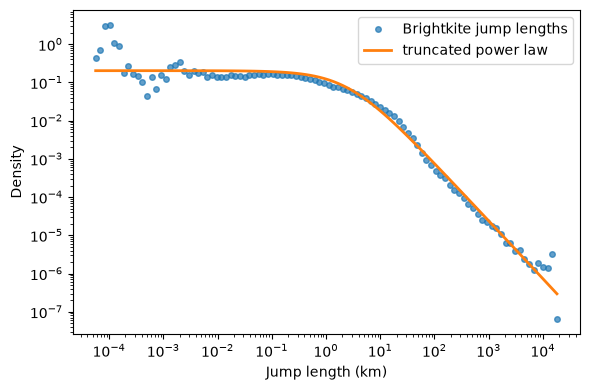

In [4]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(x, y, "o", ms=4, alpha=0.7, label="Brightkite jump lengths")
ax.loglog(x, np.exp(fastmob.log_truncated_powerlaw(x, *params)), "-", lw=2, label="truncated power law")
ax.set_xlabel("Jump length (km)")
ax.set_ylabel("Density")
ax.legend()
fig.tight_layout()